# TTFT와 total 비교

**이 노트북에서 할 일**

1. 02절 그래프를 모드 셋으로 한 번 실행하며, 사건마다 받은 시각을 적습니다.
2. 적은 시각으로 첫 사건 시간, 첫 토큰 도착 시간, 전체 걸린 시간을 계산합니다.
3. 세 시각의 차례와 요청 한 번의 예상 비용을 보고, 모드 목록의 차례만 바꿔 다시 실행합니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 3절과 9절에서 한 번씩, 모두 2번입니다.
요금표로 어림한 예상 비용은 두 요청을 합쳐 0.001달러 아래이고, 청구 금액이 아닙니다.
이 절은 걸린 시간이 주제라서, 시간을 실제로 잽니다.
잰 초와 답 글, 스트림 청크 수는 실행마다 달라질 수 있습니다.

읽거나 쓰는 파일은 없고, 체크포인터도 쓰지 않습니다.
앞에서 배운 함수 셋은 도구 파일 `stream_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 langchain 1.4.0과 langchain-openai 1.6.0입니다.
langgraph 1.2.11과 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~6절을 읽습니다.
02절 그래프에 시각을 적는 함수를 붙여, 세 시간을 하나씩 재는 자리입니다.
7~9절은 세 시간을 모아 보고, 예상 비용과 목록 차례를 바꾼 실행을 보는 자리입니다.
7~9절은 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch25-streaming`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 여섯 상자가 화살표로 이어진 그림입니다. 파란 상자 시작 시각 stream을 부르기 직전에서 노란 상자 자리 1 custom 진행 값 30 모델 요청 전 여기까지 첫 사건 시간, 노란 상자 자리 2 messages 글자 없는 스트림 청크, 노란 상자 자리 3 messages 글자가 든 첫 스트림 청크 여기까지 첫 토큰 도착 시간으로 이어집니다. 그 뒤 스트림 청크들과 둘째 진행 값을 지나 노란 상자 맨 끝 updates 노드 write_answer의 갱신, 파란 상자 끝 시각 for가 끝난 뒤 여기까지 전체 걸린 시간으로 이어지는 그림](attachment:03-1-세-시간을-재는-자리.png)

위에서 아래로 한 실행의 차례대로 읽습니다.
파란 상자는 우리 함수가 시각을 적은 자리이고, 노란 상자는 노트북 3~6절 출력으로 확인한 사건입니다.
세 시간은 모두 맨 위 시작 시각부터 재며, 어디까지 재는지는 상자 셋의 끝줄에 적었습니다.
초 값은 실행마다 달라, 그림에 적지 않았습니다.
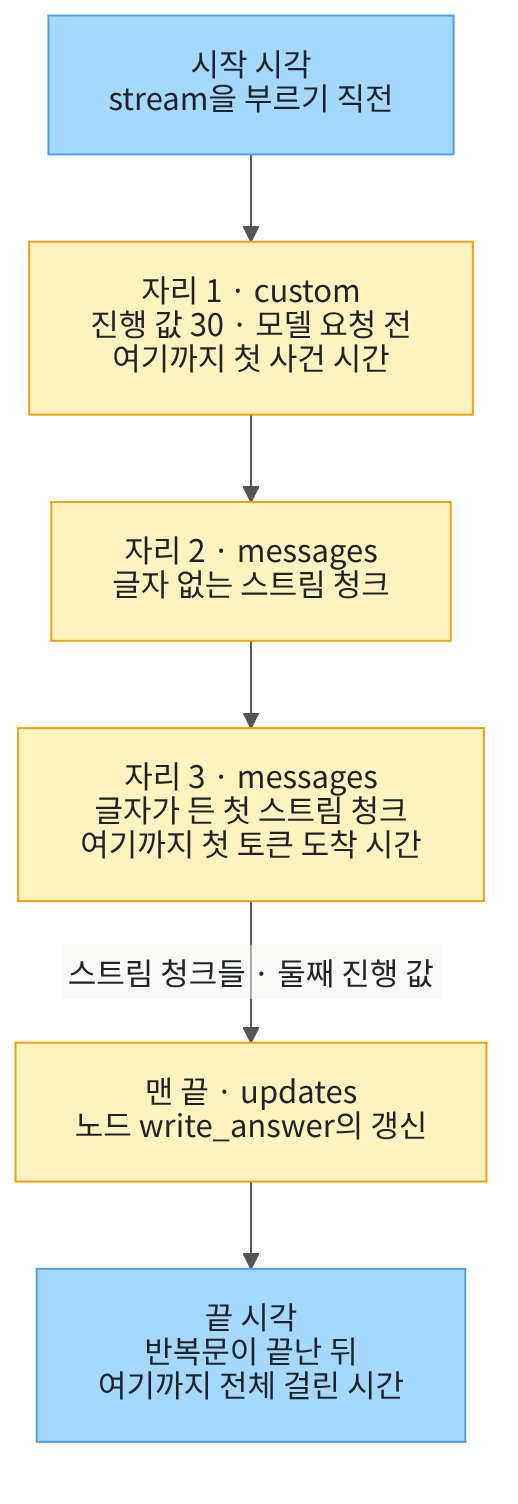

## 1. 준비

02절에서는 모드 셋을 한 실행에서 함께 받아, 사건이 나온 차례를 보았습니다.
이 절은 같은 그래프를 한 번 실행하며, 사건마다 받은 시각을 적어 걸린 시간을 잽니다.
절 제목의 TTFT는 Ch 15 05절에서 배운 첫 토큰 도착 시간(time to first token)입니다.
절 제목의 total은 그래프 실행을 시작한 때부터 끝날 때까지 걸린 시간입니다.
본문에서는 이 시간을 전체 걸린 시간이라고 씁니다.

첫 셀은 패키지 넷을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`과 `langgraph: 1.2.11`이 보입니다.
네 판 모두 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
첫 줄 `import time`은 시각을 읽는 함수 `time.perf_counter`가 든 기능 묶음을 가져옵니다.
Ch 6 06절과 Ch 15 05절에서 걸린 초를 잴 때 쓴 함수입니다.
그다음 줄들은 02절과 같은 이름이고, 마지막 가져오기 줄은 앞에서 배운 함수 셋을 도구 파일에서 가져옵니다.

In [2]:
# 시각을 읽는 기능 묶음(Ch 6 06절)과, 02절 그래프를 만드는 이름을 가져옵니다
import time
from typing_extensions import TypedDict
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, END
from langgraph.config import get_stream_writer
# 앞에서 배운 함수 셋은 도구 파일에서 가져옵니다
from stream_tools import estimate_cost, mode_order, positions_of

print("도구 파일에서 가져온 함수:", "estimate_cost, mode_order, positions_of")

도구 파일에서 가져온 함수: estimate_cost, mode_order, positions_of


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, mode_order, positions_of`가 보입니다.
함수 `positions_of`는 01절 노트북 4절, `mode_order`는 02절 노트북 4절에서 처음 적었습니다.
함수 `estimate_cost`는 Ch 6 06절에서 배웠고, 사용량 딕셔너리와 세 요금을 받아 예상 비용(달러)을 내놓습니다.
이 함수는 Ch 21 도구 파일 `runner_tools.py`에 있던 같은 이름 함수를 그대로 옮겼습니다.

앞에서 배운 함수는 `stream_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-25에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.

## 2. 02절과 같은 그래프

걸린 시간을 재려면, 02절에서 사건 차례를 본 그 그래프에 같은 요청을 보내야 합니다.
그래서 이 절은 02절 그래프를 다시 만듭니다.
다음 네 셀은 02절 노트북 2절의 네 셀과 같은 코드입니다.
노드가 노트북의 모델 객체와 시스템 메시지 글을 읽어서, 도구 파일로 옮기지 않았습니다.
먼저 칸 `question`과 `answer`를 둔 상태 형식을 만듭니다.

In [5]:
# 문의 글과 모델이 쓴 답 글 칸을 둔 상태 형식을 만듭니다(Ch 13 01절 모양, 두 칸 모두 규칙 없음)
class AnswerState(TypedDict):
    question: str
    answer: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 02절과 같은 시스템 메시지 글을 정합니다.

In [6]:
# 모델에게 줄 시스템 메시지 글을 정합니다(답을 두 문장으로 짧게 받으려고)
system_text = "배송 문의에 답하는 안내 도우미입니다. 두 문장의 한국어로 답하세요."
print("시스템 메시지 글:", system_text)

시스템 메시지 글: 배송 문의에 답하는 안내 도우미입니다. 두 문장의 한국어로 답하세요.


**결과 읽기** — 출력 줄 `시스템 메시지 글: 배송 문의에 답하는 안내 도우미입니다. 두 문장의 한국어로 답하세요.`가 보입니다.
답을 두 문장으로 부탁해, 모델의 답이 짧게 끝나게 했습니다.

다음 셀은 02절의 노드 `write_answer`입니다.
모델 요청 앞에 진행 값 30을, 뒤에 진행 값 100을 보냅니다.

In [7]:
# 모델 요청 앞뒤에 진행 값을 보내고, 모델이 쓴 답 글을 칸 answer에 내는 노드입니다
def write_answer(state):
    writer = get_stream_writer()
    writer({"stage": "before_model", "progress": 30})
    messages = [("system", system_text), ("user", state["question"])]
    # 모델 요청은 이 줄에서 한 번 나가고, 답을 다 받은 뒤에 다음 줄로 갑니다
    response = model.invoke(messages)
    writer({"stage": "after_model", "progress": 100})
    return {"answer": response.text}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
진행 값 30은 모델 요청을 보내기 전에 나갑니다.
그래서 이 절의 첫 사건은 모델의 답을 기다리지 않고 나올 것입니다.

다음 셀은 노드 하나를 START → write_answer → END로 이어, 체크포인터 없이 컴파일합니다.

In [8]:
# 노드 하나를 START → write_answer → END로 잇고, 체크포인터 없이 컴파일합니다
builder = StateGraph(AnswerState)
builder.add_node("write_answer", write_answer)
builder.add_edge(START, "write_answer")
builder.add_edge("write_answer", END)
graph = builder.compile()
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['write_answer']


**결과 읽기** — 출력 줄 `등록한 노드: ['write_answer']`가 보입니다.

## 3. 사건마다 시각 적기

시각은 시계를 읽은 값이고, 걸린 시간은 두 시각의 차이입니다.
함수 `time.perf_counter()`가 내놓는 수는 그 하나만으로는 뜻이 없습니다.
두 번 읽어 뒤 값에서 앞 값을 빼야 그 사이에 걸린 초가 됩니다.

01절 함수 `collect_events`는 사건을 다 모은 뒤에 목록을 내놓아, 사건마다 받은 때를 알 수 없습니다.
다음 셀의 함수 `collect_timed_events`는 사건을 꺼낼 때마다 그때의 시각을 하나씩 적습니다.
메서드 `stream`을 부르기 직전에 시작 시각을, 반복문 `for`가 끝난 뒤에 끝 시각을 적습니다.
네 가지를 딕셔너리 하나에 담아 내놓습니다.

In [9]:
# 그래프를 한 번 실행하며, 사건을 꺼낼 때마다 그때의 시각을 적어 딕셔너리로 내놓습니다
def collect_timed_events(graph_to_run, graph_input, config, modes):
    # 메서드 stream을 부르기 직전의 시각을 시작 시각으로 적습니다
    timed_run = {"start": time.perf_counter(), "events": [], "times": []}
    for event in graph_to_run.stream(graph_input, config, stream_mode=modes):
        timed_run["events"].append(event)
        # 사건을 담은 바로 뒤에 시각을 적어, 두 목록의 자리를 맞춥니다
        timed_run["times"].append(time.perf_counter())
    timed_run["end"] = time.perf_counter()
    return timed_run

**결과 읽기** — 정의 셀이라 출력이 없습니다.
키 `start`와 `end`에는 시작 시각과 끝 시각이 하나씩 들어갑니다.
키 `events`와 `times`에는 사건과 시각이 같은 자리끼리 짝을 이루어 들어갑니다.
01절에서 본 것처럼, 메서드 `stream`을 부르기만 해서는 실행이 시작되지 않습니다.
실행은 반복문이 첫 사건을 꺼낼 때 시작됩니다.

다음 셀은 02절과 같은 문의로 그래프를 한 번 실행합니다(모델 요청 1번).
모드 목록도 02절과 같은 `["messages", "updates", "custom"]`입니다.
모드마다 따로 요청하지 않고, 한 요청 안에서 세 시간을 모두 잽니다.

In [10]:
# 모드 셋을 한 목록으로 골라 한 번 실행하며, 사건마다 시각을 적습니다(모델 요청 1번)
answer_input = {"question": "주문한 책이 아직 오지 않았어요. 언제 받을 수 있나요?", "answer": ""}
answer_modes = ["messages", "updates", "custom"]
# 체크포인터가 없어 설정 자리에는 None을 넘깁니다(02절과 같음)
timed_run = collect_timed_events(graph, answer_input, None, answer_modes)
answer_events = timed_run["events"]
event_times = timed_run["times"]
print("받은 사건 수:", len(answer_events))
print("사건마다 시각이 하나씩인가:", len(answer_events) == len(event_times))
print("모드 차례:", mode_order(answer_events))

받은 사건 수: 43
사건마다 시각이 하나씩인가: True
모드 차례: ['custom', 'messages', 'custom', 'updates']


**결과 읽기** — 출력 줄 `사건마다 시각이 하나씩인가: True`와 `모드 차례: ['custom', 'messages', 'custom', 'updates']`가 보입니다.
사건 목록과 시각 목록의 길이가 같아, 자리마다 사건 하나와 시각 하나가 짝을 이룹니다.
모드 차례는 02절처럼 진행 값, 스트림 청크들, 진행 값, 갱신의 차례입니다.

이번 실행에서는 출력 줄 `받은 사건 수: 43`입니다.
모델의 답이 몇 개의 스트림 청크로 나뉘어 오느냐에 따라, 이 수는 달라질 수 있습니다.

## 4. 첫 사건 시간

첫 사건 시간은 메서드 `stream`을 부른 때부터, 모드와 관계없이 처음 받은 사건까지 걸린 시간입니다.
가게에 전화를 걸고 「잠시만 기다려 주세요」라는 말을 듣기까지 걸린 시간과 같습니다.
이 절 코드에서는 시각 목록의 첫 값 `event_times[0]`에서 시작 시각을 뺀 초입니다.

다음 셀은 첫 사건의 모드와 자료, 첫 사건 시간을 봅니다.
실행 전에 예상해 봅니다.
첫 사건은 모델 요청 전에 보낸 진행 값 30일 것입니다.

In [11]:
# 첫 사건의 모드와 자료를 보고, 시작부터 첫 사건까지 걸린 시간(초)을 계산합니다
start_time = timed_run["start"]
first_event_seconds = round(event_times[0] - start_time, 3)
print("첫 사건의 모드 이름:", answer_events[0][0])
print("첫 사건의 자료:", answer_events[0][1])
print("첫 사건 시간(초):", first_event_seconds)

첫 사건의 모드 이름: custom
첫 사건의 자료: {'stage': 'before_model', 'progress': 30}
첫 사건 시간(초): 0.003


**결과 읽기** — 출력 줄 `첫 사건의 모드 이름: custom`과 `첫 사건의 자료: {'stage': 'before_model', 'progress': 30}`이 보입니다.
예상대로 첫 사건은 모델 요청 앞에 보낸 진행 값입니다.
그래서 첫 사건 시간에는 모델의 답을 기다린 시간이 들어 있지 않습니다.
화면은 이 사건을 받자마자 「답을 쓰는 중」 같은 표시를 띄울 수 있습니다.

이번 실행에서는 출력 줄 `첫 사건 시간(초): 0.003`입니다.
잰 초는 기기와 네트워크, 실행한 때에 따라 달라집니다.

## 5. 첫 토큰 도착 시간

Ch 15 05절에서 첫 토큰 도착 시간은 답의 첫 글자를 받기까지 걸린 시간이었습니다.
그 절은 모델의 `stream()`을 부르기 직전부터, 글자가 든 첫 스트림 청크가 도착할 때까지로 쟀습니다.
이 절은 그보다 조금 앞인, 그래프의 메서드 `stream`을 부르기 직전부터 잽니다.
02절 5절에서 본 대로, 모드 `messages`의 첫 스트림 청크에는 글자가 없었습니다.
그래서 모드 `messages`의 첫 사건과 글자가 든 첫 스트림 청크를 나눠 봅니다.

다음 셀은 모드 `messages`의 첫 사건이 몇 번째인지와, 그 스트림 청크의 글자 수를 봅니다.

In [12]:
# 모드 messages의 첫 사건이 몇 번째인지와, 그 스트림 청크의 글자 수를 봅니다(01절 함수 positions_of)
message_places = positions_of(answer_events, "messages")
first_message = answer_events[message_places[0] - 1][1]
print("모드 messages 첫 사건의 자리:", message_places[0])
print("그 스트림 청크의 글자 수:", len(first_message[0].text))

모드 messages 첫 사건의 자리: 2
그 스트림 청크의 글자 수: 0


**결과 읽기** — 출력 줄 `모드 messages 첫 사건의 자리: 2`와 `그 스트림 청크의 글자 수: 0`이 보입니다.
진행 값 30 바로 다음에 모드 `messages`의 사건이 왔지만, 그 스트림 청크에는 글자가 없었습니다.
이 사건의 시각을 쓰면, 답의 글자가 오기 전의 시각을 재게 됩니다.

다음 셀은 글자가 든 첫 스트림 청크가 몇 번째 사건인지 찾는 함수입니다.
사건을 앞에서부터 보다가, 모드가 `messages`이고 스트림 청크의 글이 빈 글이 아닌 첫 사건에서 멈춥니다.
끝까지 찾지 못하면 `None`을 내놓습니다.

In [13]:
# 사건 목록에서 글자가 든 첫 스트림 청크가 몇 번째(1부터 셈) 사건인지 내놓습니다
def first_text_place(events):
    for index in range(len(events)):
        mode = events[index][0]
        data = events[index][1]
        # 모드 messages의 자료는 (스트림 청크, 칸 metadata) 짝이라, [0]이 스트림 청크입니다
        if mode == "messages" and data[0].text != "":
            return index + 1
    # 끝까지 찾지 못하면 None을 내놓습니다
    return None

**결과 읽기** — 정의 셀이라 출력이 없습니다.
두 조건을 `and`로 이어, 둘 다 맞을 때만 자리를 내놓습니다.
모드 `custom`의 자료는 딕셔너리라서, 모드를 먼저 보고 나서 스트림 청크의 글을 봅니다.

다음 셀은 이 함수로 자리를 찾고, 그 사건의 시각으로 첫 토큰 도착 시간을 계산합니다.

In [14]:
# 글자가 든 첫 스트림 청크의 자리를 찾고, 시작부터 그 사건까지 걸린 시간(초)을 계산합니다
text_place = first_text_place(answer_events)
# 자리는 1부터 세므로, 시각 목록에서는 한 칸 앞 [text_place - 1]에 있습니다
text_time = event_times[text_place - 1]
first_token_seconds = round(text_time - start_time, 3)
print("글자가 든 첫 스트림 청크의 자리:", text_place)
print("첫 토큰 도착 시간(초):", first_token_seconds)

글자가 든 첫 스트림 청크의 자리: 3
첫 토큰 도착 시간(초): 1.51


**결과 읽기** — 출력 줄 `글자가 든 첫 스트림 청크의 자리: 3`이 보입니다.
모드 `messages`의 둘째 사건부터 답의 글자가 왔습니다.
첫 토큰 도착 시간은 이 셋째 사건의 시각에서 시작 시각을 뺀 값입니다.

이번 실행에서는 출력 줄 `첫 토큰 도착 시간(초): 1.51`입니다.
4절의 첫 사건 시간과 달리, 모델 요청을 보내고 첫 글자를 받기까지 기다린 시간이 들어 있습니다.

## 6. 전체 걸린 시간

전체 걸린 시간은 메서드 `stream`을 부른 때부터 마지막 사건까지 다 받고 끝날 때까지 걸린 시간입니다.
가게 전화로 치면, 안내를 끝까지 듣고 전화를 끊을 때까지 걸린 시간입니다.
이 절 코드에서는 반복문이 끝난 뒤 적은 끝 시각에서 시작 시각을 뺀 초입니다.
Ch 15 05절은 같은 시간을 다른 이름으로 불렀고, 이 챕터는 전체 걸린 시간이라고 씁니다.

다음 셀은 마지막 사건의 모드와 전체 걸린 시간을 봅니다.
자리 `-1`은 목록의 맨 끝 자리입니다.

In [15]:
# 마지막 사건의 모드를 보고, 시작부터 끝 시각까지 걸린 시간(초)을 계산합니다
end_time = timed_run["end"]
total_seconds = round(end_time - start_time, 3)
# 자리 -1은 목록의 맨 끝 사건입니다
print("마지막 사건의 모드 이름:", answer_events[-1][0])
print("전체 걸린 시간(초):", total_seconds)

마지막 사건의 모드 이름: updates
전체 걸린 시간(초): 1.758


**결과 읽기** — 출력 줄 `마지막 사건의 모드 이름: updates`가 보입니다.
노드가 끝나며 낸 갱신이 마지막 사건이고, 칸 `answer`의 답 글 전체가 여기에 담겨 옵니다.
끝 시각은 이 갱신을 받고 반복문이 끝난 뒤에 적었습니다.

이번 실행에서는 출력 줄 `전체 걸린 시간(초): 1.758`입니다.

## 7. 세 시간 모아 보기

세 시각은 사건을 받은 차례대로 적었습니다.
첫 사건은 자리 1, 글자가 든 첫 스트림 청크는 자리 3이고, 끝 시각은 마지막 사건 뒤에 적었습니다.
실행 전에 예상해 봅니다.
앞 사건의 시각을 먼저 적었으니, 다음 셀의 두 비교는 모두 `True`일 것입니다.

In [16]:
# 세 시각을 차례대로 견줍니다(사건을 받은 차례로 정해지는 크기 관계)
print("첫 사건 시각이 글자가 든 첫 스트림 청크 시각보다 앞인가:", event_times[0] < text_time)
print("글자가 든 첫 스트림 청크 시각이 끝 시각보다 앞인가:", text_time < end_time)

첫 사건 시각이 글자가 든 첫 스트림 청크 시각보다 앞인가: True
글자가 든 첫 스트림 청크 시각이 끝 시각보다 앞인가: True


**결과 읽기** — 두 출력 줄이 모두 `True`입니다.
그래서 세 시간은 첫 사건 시간, 첫 토큰 도착 시간, 전체 걸린 시간의 차례로 커집니다.
이 차례는 사건이 나온 차례로 정해지므로, 초 값이 달라져도 같습니다.
Ch 15 05절 출력 「첫 토큰이 끝보다 먼저 왔는가: True」와 같은 모양입니다.

다음 셀은 세 시간을 한 딕셔너리로 계산하는 함수입니다.
4~6절에서 하나씩 한 계산을 묶어, 9절의 다른 실행에도 그대로 씁니다.

In [17]:
# 시각을 적은 실행 기록(collect_timed_events의 결과)에서 세 시간(초)을 계산해 딕셔너리로 내놓습니다
def three_times(run_record):
    start_at = run_record["start"]
    # 5절 함수로 글자가 든 첫 스트림 청크의 자리를 찾습니다
    place = first_text_place(run_record["events"])
    text_at = run_record["times"][place - 1]
    seconds = {"첫 사건 시간": round(run_record["times"][0] - start_at, 3)}
    seconds["첫 토큰 도착 시간"] = round(text_at - start_at, 3)
    seconds["전체 걸린 시간"] = round(run_record["end"] - start_at, 3)
    return seconds

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 안에서 5절 함수 `first_text_place`를 불러, 글자가 든 첫 스트림 청크의 자리를 찾습니다.
그래서 이 셀보다 5절의 함수 셀을 먼저 실행해 두어야 합니다.

다음 셀은 3절 실행의 세 시간을 이 함수로 계산하고, 4~6절 값과 견줍니다.

In [18]:
# 3절 실행의 세 시간을 함수로 계산하고, 4~6절에서 하나씩 계산한 값과 견줍니다
answer_seconds = three_times(timed_run)
earlier_seconds = {"첫 사건 시간": first_event_seconds}
earlier_seconds["첫 토큰 도착 시간"] = first_token_seconds
earlier_seconds["전체 걸린 시간"] = total_seconds
print("세 시간(초):", answer_seconds)
print("4~6절에서 계산한 값과 같은가:", answer_seconds == earlier_seconds)

세 시간(초): {'첫 사건 시간': 0.003, '첫 토큰 도착 시간': 1.51, '전체 걸린 시간': 1.758}
4~6절에서 계산한 값과 같은가: True


**결과 읽기** — 출력 줄 `4~6절에서 계산한 값과 같은가: True`가 보입니다.
라벨 `세 시간(초):` 뒤 딕셔너리의 세 값은 4~6절 출력의 세 값과 같습니다.
같은 실행의 같은 시각으로 같은 계산을 했기 때문입니다.

다음 셀은 첫 토큰 도착 시간을 기준으로, 전체 걸린 시간을 두 구간으로 나눠 봅니다.
앞 구간은 사용자가 첫 글자를 기다리는 시간입니다.
뒤 구간은 글자가 이어 붙는 것을 지켜보는 시간입니다.

In [19]:
# 첫 글자를 받기까지 기다린 시간과, 첫 글자 뒤 끝날 때까지 걸린 시간을 나눠 봅니다
after_text_seconds = round(end_time - text_time, 3)
print("구간 | 초")
print("시작부터 첫 글자까지 |", first_token_seconds)
print("첫 글자부터 끝까지 |", after_text_seconds)

구간 | 초
시작부터 첫 글자까지 | 1.51
첫 글자부터 끝까지 | 0.248


**결과 읽기** — 라벨 줄 `구간 | 초` 아래 두 줄이 두 구간입니다.
두 구간을 더하면 6절의 전체 걸린 시간과 거의 같고, 반올림 때문에 끝자리가 다를 수 있습니다.

이번 실행에서는 첫 글자까지 1.51초, 첫 글자부터 끝까지 0.248초였습니다.
두 구간의 크기는 답 길이와 실행한 때에 따라 달라져, 이 절의 결론에 쓰지 않습니다.
스트리밍하지 않은 실행과는 견주지 않아, 스트리밍이 기다림을 줄이는지도 이 결과로 말할 수 없습니다.

## 8. 사용량과 예상 비용

Ch 6 06절은 걸린 초와 함께 요청 한 번의 예상 비용을 셌습니다.
이 절도 3절 요청 한 번의 사용량으로 예상 비용을 셉니다.
02절 5절에서 본 대로, 사용량은 스트림 청크 하나에만 들어 있었습니다.
다음 셀은 사용량이 든 스트림 청크를 찾아 토큰 수를 봅니다.

In [20]:
# 사용량이 든 스트림 청크를 찾아, 3절 요청 한 번의 토큰 수를 봅니다
answer_usage = None
usage_count = 0
for mode, data in answer_events:
    if mode == "messages" and data[0].usage_metadata is not None:
        answer_usage = data[0].usage_metadata
        usage_count = usage_count + 1
print("사용량이 든 스트림 청크 수:", usage_count)
print("입력 토큰 수:", answer_usage["input_tokens"])
print("캐시 입력 토큰 수:", answer_usage["input_token_details"]["cache_read"])
print("출력 토큰 수:", answer_usage["output_tokens"])

사용량이 든 스트림 청크 수: 1
입력 토큰 수: 47
캐시 입력 토큰 수: 0
출력 토큰 수: 40


**결과 읽기** — 출력 줄 `사용량이 든 스트림 청크 수: 1`과 `입력 토큰 수: 47`이 보입니다.
사용량이 든 스트림 청크가 하나라, 그 사용량이 이 요청 한 번의 사용량입니다.
출력 줄 `캐시 입력 토큰 수: 0`이라, 입력 토큰은 모두 일반 입력 요금으로 셉니다.

이번 실행에서는 출력 줄 `출력 토큰 수: 40`입니다.
출력 토큰 수는 모델이 쓴 답 글에 따라 실행마다 달라질 수 있습니다.

다음 셀은 Ch 6 06절 요금표와 확인한 날짜를 적습니다.
요금은 모델 `gpt-5.4-mini`의 100만 토큰당 달러입니다.

In [21]:
# Ch 6 06절 요금표(100만 토큰당 달러)와 확인한 날짜를 적습니다
pricing_date = "2026-09-17"
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
print("요금 확인 날짜:", pricing_date)
print("mini 요금:", mini_prices)

요금 확인 날짜: 2026-09-17
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-17`이 보입니다.
라벨 `mini 요금:` 뒤 딕셔너리는 일반 입력, 캐시 입력, 출력 토큰의 100만 개당 달러입니다.
출력 요금은 셀에 4.50으로 적었지만, 출력에서는 끝자리 0 없이 찍힙니다.

다음 셀은 함수 `estimate_cost`에 3절 사용량과 세 요금을 넣어 예상 비용을 셉니다.

In [22]:
# 3절 요청 한 번의 예상 비용(달러)을 셉니다(Ch 6 06절 함수 estimate_cost)
answer_cost = estimate_cost(
    answer_usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"]
)
print("예상 비용(달러):", round(answer_cost, 6))

예상 비용(달러): 0.000215


**결과 읽기** — 라벨 `예상 비용(달러):` 뒤 값이 요금표로 어림한 예상 비용이고, 청구 금액이 아닙니다.
세 요금은 식 안에 숫자로 적지 않고, 앞 셀의 딕셔너리에서 꺼내 넣었습니다.

이번 실행에서는 `0.000215`달러였습니다.
출력 토큰 수가 달라지면 이 값도 달라집니다.
이 노트북은 모델 요청을 두 번 보내므로, 노트북 한 번의 예상 비용은 이 값의 두 배쯤입니다.

## 9. 값 바꿔 보기 · 모드 목록의 차례만 바꾸기

값 하나만 바꿔 봅니다.
바꿀 값은 모드 목록의 차례이고, 3절 목록을 `["updates", "messages", "custom"]`으로 바꿉니다.
실행 전에 예상해 봅니다.
사건 차례는 노드 코드가 정하니, 모드 `updates`를 앞에 적어도 첫 사건은 진행 값 30일 것입니다.
글자가 든 첫 스트림 청크의 자리도 3 그대로일 것입니다.

다음 셀은 같은 문의로 그래프를 한 번 더 실행합니다(모델 요청 1번).

In [23]:
# 모드 목록의 차례만 바꿔, 같은 문의로 한 번 더 실행하며 시각을 적습니다(모델 요청 1번)
swapped_modes = ["updates", "messages", "custom"]
swapped_run = collect_timed_events(graph, answer_input, None, swapped_modes)
swapped_events = swapped_run["events"]
print("모드 차례:", mode_order(swapped_events))
print("첫 사건의 자료:", swapped_events[0][1])
print("글자가 든 첫 스트림 청크의 자리:", first_text_place(swapped_events))

모드 차례: ['custom', 'messages', 'custom', 'updates']
첫 사건의 자료: {'stage': 'before_model', 'progress': 30}
글자가 든 첫 스트림 청크의 자리: 3


**결과 읽기** — 출력 줄 `모드 차례: ['custom', 'messages', 'custom', 'updates']`는 3절과 같습니다.
출력 줄 `첫 사건의 자료: {'stage': 'before_model', 'progress': 30}`도 3절과 같습니다.
출력 줄 `글자가 든 첫 스트림 청크의 자리: 3`도 5절과 같습니다.
목록에서 모드 `updates`를 맨 앞에 적었지만, 첫 사건은 여전히 진행 값이었습니다.
모드 목록은 받을 모드를 고를 뿐이고, 사건 차례는 노드 코드가 정합니다.

다음 셀은 두 실행의 세 시간을 한 줄씩 견줍니다.

In [24]:
# 두 실행의 세 시간(초)을 한 줄씩 견줍니다(7절 함수 three_times)
swapped_seconds = three_times(swapped_run)
print("시간 | 3절 실행 | 목록 차례를 바꾼 실행")
for name in answer_seconds:
    print(name, "|", answer_seconds[name], "|", swapped_seconds[name])

시간 | 3절 실행 | 목록 차례를 바꾼 실행
첫 사건 시간 | 0.003 | 0.003
첫 토큰 도착 시간 | 1.51 | 0.642
전체 걸린 시간 | 1.758 | 0.84


**결과 읽기** — 라벨 줄 `시간 | 3절 실행 | 목록 차례를 바꾼 실행` 아래 세 줄이 두 실행의 세 시간입니다.
두 실행 모두 사건 차례가 같아, 세 값이 위에서 아래로 커집니다.

이번 실행에서는 줄 `첫 토큰 도착 시간 | 1.51 | 0.642`와 `전체 걸린 시간 | 1.758 | 0.84`입니다.
두 요청은 따로 보낸 요청이라, 초의 차이를 모드 목록 차례 탓으로 읽지 않습니다.

## 정리

1. 모드 셋을 한 실행에서 함께 받으며 사건마다 시각을 적자, 한 요청 안에서 세 시간을 모두 잴 수 있었습니다.
2. 첫 사건은 모델 요청 전의 진행 값이었고, 글자가 든 첫 스트림 청크는 셋째 사건이었습니다.
3. 세 시각은 사건 차례대로 커졌고, 모드 목록의 차례를 바꿔도 사건 차례는 같았습니다.

04절 실습에서는 이 챕터에서 배운 것을 작은 흐름 하나에 모아 실행합니다.